# HW1 — Introduction and Learnability: PAC vs. Agnostic PAC

**Statistical and Machine Learning** — M2 IM / IMDS / MIAGE, Université de Haute-Alsace

**Author:** Amina MENACER

---

**Goal.** Illustrate experimentally the difference between the PAC (realizable) and the Agnostic PAC learning frameworks, using an Empirical Risk Minimization (ERM) learner over the class of threshold classifiers on $\mathcal{X} = [0,1]$.

**Outline**
0. Setup and experimental parameters
1. Data generation
2. Implementation of ERM
3. Performance evaluation (empirical vs. true error)
4. Experimental verification of PAC learning
5. From PAC to Agnostic PAC
6. Conclusion

Only `numpy` and `matplotlib` are used; the learning algorithm is implemented from scratch.

## 0. Setup and experimental parameters

**Learning problem.** $\mathcal{X}=[0,1]$, $x \sim \mathcal{U}[0,1]$, target $f_\theta(x) = \mathbb{1}[x>\theta]$.
Hypothesis class $\mathcal{H} = \{h_t(x) = \mathbb{1}[x>t] : t \in [0,1]\}$.
The realizability assumption holds in Sections 1–4 since $f_\theta \in \mathcal{H}$.

**Parameter choices (and why).**

| Parameter | Value | Justification |
|---|---|---|
| $\theta$ | 0.3 | Away from the centre and from the borders; any $\theta \in (\varepsilon, 1)$ gives the same behaviour (shown below). |
| $\varepsilon$ | 0.05 | A 5% error tolerance: demanding enough that small samples fail, loose enough that the transition is visible within $m \le 200$. |
| $\delta$ | 0.05 | 95% confidence, a standard choice. |
| $\eta$ | 0.1 (main), sweep over $\{0.05, 0.1, 0.2, 0.3\}$ | Moderate noise for the main comparison; the sweep shows how noise changes the picture. |
| $m$ | $\{5,10,20,50,100,200\}$ (required) + a finer grid up to 500 | The required grid for the tables, a denser grid for smooth curves. |
| Repetitions $R$ | 1000 | Monte Carlo standard error of a probability $p$ is $\sqrt{p(1-p)/R} \le 0.016$. |
| Test set size | 100 000 | Standard error of the test error $\le \sqrt{0.25/10^5} \approx 0.0016$. |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

THETA = 0.3          # target threshold
EPS = 0.05           # accuracy parameter epsilon
DELTA = 0.05         # confidence parameter delta
ETA = 0.1            # label-noise rate for the agnostic setting
ETAS = [0.05, 0.1, 0.2, 0.3]
M_GRID = [5, 10, 20, 50, 100, 200]                                       # required sizes
M_FINE = np.unique(np.round(np.geomspace(5, 500, 30)).astype(int))     # smooth curves
R = 1000             # Monte Carlo repetitions
N_TEST = 100_000     # size of the independent test set

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Data generation

Each example is drawn as $x \sim \mathcal{U}[0,1]$ and labelled $y = f_\theta(x)$.
In the agnostic setting each label is independently flipped with probability $\eta$:
$y = f_\theta(x) \oplus b$ with $b \sim \text{Bernoulli}(\eta)$.

The generator works on a batch of $R$ independent samples at once (array of shape `(R, m)`), which makes the Monte Carlo experiments of Sections 4–5 fast.

In [2]:
def generate_data(m, theta=THETA, eta=0.0, n_rep=None, rng=rng):
    # Draw training samples. Returns X, y of shape (m,) or (n_rep, m).
    shape = (m,) if n_rep is None else (n_rep, m)
    X = rng.random(shape)
    y = (X > theta).astype(np.int8)
    if eta > 0:
        flip = rng.random(shape) < eta
        y = y ^ flip.astype(np.int8)
    return X, y

datasets = {m: generate_data(m) for m in M_GRID}                    # realizable
datasets_noisy = {m: generate_data(m, eta=ETA) for m in M_GRID}     # agnostic
for m in M_GRID:
    X, y = datasets[m]
    print(f"m={m:>3}: {y.sum():>3} positive / {m - y.sum():>3} negative examples")

m=  5:   4 positive /   1 negative examples
m= 10:   9 positive /   1 negative examples
m= 20:  15 positive /   5 negative examples
m= 50:  33 positive /  17 negative examples
m=100:  71 positive /  29 negative examples
m=200: 136 positive /  64 negative examples


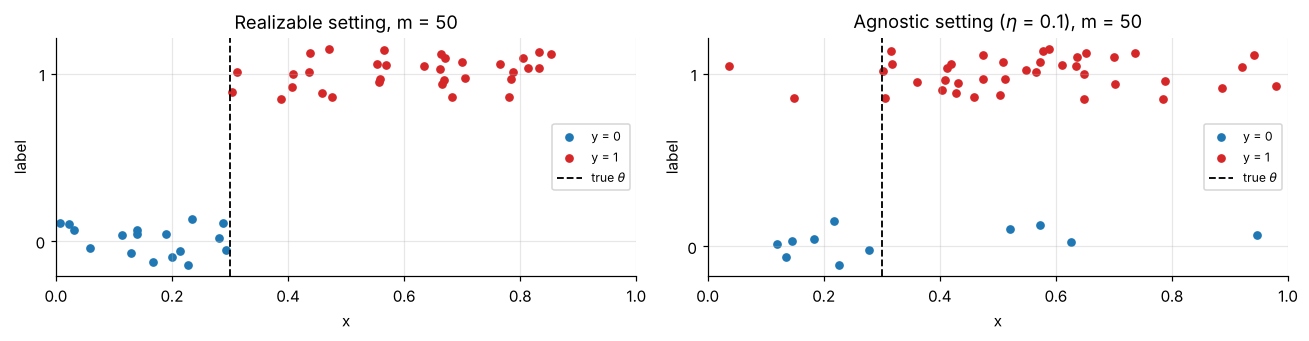

In [3]:
def plot_dataset(ax, X, y, title, theta=THETA, t_hat=None):
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, size=len(X))
    ax.scatter(X[y == 0], y[y == 0] + jitter[y == 0], c="tab:blue", s=22, label="y = 0")
    ax.scatter(X[y == 1], y[y == 1] + jitter[y == 1], c="tab:red", s=22, label="y = 1")
    ax.axvline(theta, color="k", ls="--", lw=1.2, label=r"true $\theta$")
    if t_hat is not None:
        ax.axvline(t_hat, color="tab:green", lw=1.5, label=r"ERM $\hat t$")
    ax.set_yticks([0, 1]); ax.set_xlim(0, 1); ax.set_xlabel("x"); ax.set_ylabel("label")
    ax.set_title(title); ax.legend(loc="center right", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
plot_dataset(axes[0], *datasets[50], "Realizable setting, m = 50")
plot_dataset(axes[1], *datasets_noisy[50], rf"Agnostic setting ($\eta$ = {ETA}), m = 50")
plt.tight_layout(); plt.show()

**Observation.** In the realizable setting the two classes are perfectly separated by $\theta$: every point left of the dashed line is blue, every point right of it is red. With noise, some red points appear to the left of $\theta$ and some blue points to the right; no threshold can separate this sample perfectly (unless, by chance, the flipped points happen to fall at the extremes).

## 2. Implementation of ERM

**Reducing an infinite class to $m+1$ candidates.** For a fixed sample, $h_t$ and $h_{t'}$ make exactly the same predictions on the sample whenever no training point lies in $(\min(t,t'), \max(t,t')]$. Sorting the sample $x_{(1)} \le \dots \le x_{(m)}$, the empirical risk $L_S(h_t)$ is therefore piecewise constant in $t$, and it suffices to evaluate
$$t \in \{0, x_{(1)}, \dots, x_{(m)}\}.$$
Choosing $t = x_{(k)}$ means: the $k$ smallest points are predicted $0$, the others $1$.

**Computing all $m+1$ empirical risks in $O(m \log m)$.** With $C_k = \sum_{i \le k} y_{(i)}$ (number of 1-labels among the $k$ smallest points),
$$m \, L_S\big(h_{x_{(k)}}\big) = \underbrace{C_k}_{\text{1-labels predicted 0}} + \underbrace{(m-k) - (C_m - C_k)}_{\text{0-labels predicted 1}}.$$
A single sort and a cumulative sum give all candidates at once; the ERM returns the minimiser.

**Tie-breaking.** When several candidates reach the minimum, `argmin` keeps the smallest one. Within the selected interval $[x_{(k)}, x_{(k+1)})$, we take the left endpoint $t = x_{(k)}$. In the realizable case this gives a very simple rule: $\hat t$ is **the largest training point labelled 0** (or $0$ if there is none), and it is the unique minimiser among the candidates. This choice is analysed exactly in Section 4, and an alternative (midpoint) is compared in Section 4.4.

In [4]:
def erm_threshold(X, y):
    # ERM over threshold classifiers h_t(x) = 1[x > t].
    # Works on one sample (shape (m,)) or a batch (shape (R, m)).
    # Returns (t_hat, empirical_risk).
    X = np.atleast_2d(X); y = np.atleast_2d(y)
    n_rep, m = X.shape
    order = np.argsort(X, axis=1)
    Xs = np.take_along_axis(X, order, axis=1)
    ys = np.take_along_axis(y, order, axis=1).astype(np.int32)
    C = np.concatenate([np.zeros((n_rep, 1), np.int32), np.cumsum(ys, axis=1)], axis=1)  # C_0..C_m
    k = np.arange(m + 1)
    errors = C + (m - k) - (C[:, [m]] - C)            # shape (n_rep, m+1)
    k_star = np.argmin(errors, axis=1)                # first minimiser
    candidates = np.concatenate([np.zeros((n_rep, 1)), Xs], axis=1)
    t_hat = candidates[np.arange(n_rep), k_star]
    emp_risk = errors[np.arange(n_rep), k_star] / m
    return t_hat.squeeze(), emp_risk.squeeze()

def empirical_risk(t, X, y):
    return np.mean((X > t).astype(np.int8) != y)

# Sanity check against brute force on a fine grid of thresholds
for (X, y) in [datasets[50], datasets_noisy[50], datasets_noisy[200]]:
    t_hat, ls = erm_threshold(X, y)
    grid = np.linspace(0, 1, 20001)
    brute = min(empirical_risk(t, X, y) for t in grid)
    assert abs(ls - brute) < 1e-12 and abs(ls - empirical_risk(t_hat, X, y)) < 1e-12
print("ERM matches brute-force minimisation on a 20 001-point grid.")

ERM matches brute-force minimisation on a 20 001-point grid.


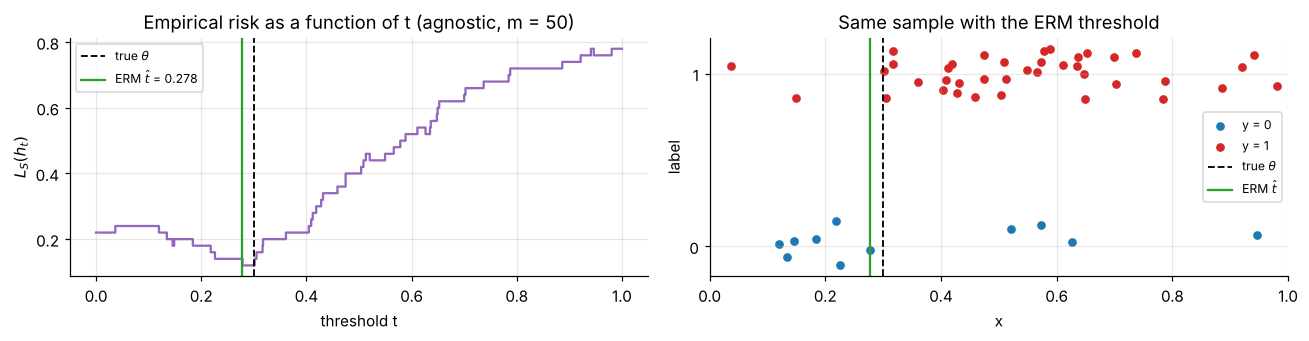

In [5]:
X, y = datasets_noisy[50]
t_hat, ls_hat = erm_threshold(X, y)
grid = np.linspace(0, 1, 2001)
risk_curve = [empirical_risk(t, X, y) for t in grid]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].step(grid, risk_curve, where="post", color="tab:purple")
axes[0].axvline(THETA, color="k", ls="--", lw=1.2, label=r"true $\theta$")
axes[0].axvline(t_hat, color="tab:green", lw=1.5, label=rf"ERM $\hat t$ = {t_hat:.3f}")
axes[0].set_xlabel("threshold t"); axes[0].set_ylabel(r"$L_S(h_t)$")
axes[0].set_title(rf"Empirical risk as a function of t (agnostic, m = 50)"); axes[0].legend(fontsize=8)
plot_dataset(axes[1], X, y, "Same sample with the ERM threshold", t_hat=t_hat)
plt.tight_layout(); plt.show()

**Observation.** $L_S(h_t)$ is a step function that only changes at training points, which is why evaluating $m+1$ candidates is enough. With noisy labels its minimum is strictly positive and $\hat t$ need not coincide with $\theta$.

## 3. Performance evaluation

**True error.** We estimate $L_{\mathcal D}(h_{\hat t})$ on an independent test set of $10^5$ points drawn from the same distribution.

**Closed-form check.** Because $x \sim \mathcal U[0,1]$, the true error is also available exactly:
- realizable: $h_t$ and $f_\theta$ disagree exactly on the interval between $t$ and $\theta$, so $L_{\mathcal D, f}(h_t) = |t-\theta|$;
- agnostic: on that interval the prediction is wrong unless the label was flipped, elsewhere it is wrong only if the label was flipped, so
$$L_{\mathcal D}(h_t) = (1-\eta)\,|t-\theta| + \eta\,(1-|t-\theta|) = \eta + (1-2\eta)\,|t-\theta|.$$

The table compares the test-set estimate with the exact value. Once they agree to within Monte Carlo error, the Monte Carlo experiments of Sections 4–5 use the exact formula, which removes test-set noise and is much faster.

In [6]:
def true_risk(t, theta=THETA, eta=0.0):
    return eta + (1 - 2 * eta) * np.abs(t - theta)

X_test, y_test = generate_data(N_TEST)
X_test_n, y_test_n = generate_data(N_TEST, eta=ETA)

def evaluation_table(data, X_te, y_te, eta, label):
    print(f"--- {label} ---")
    print(f"{'m':>4} | {'t_hat':>7} | {'L_S (train)':>11} | {'L_D (test set)':>14} | {'L_D (exact)':>11} | {'gap L_D - L_S':>13}")
    for m in M_GRID:
        X, y = data[m]
        t_hat, ls = erm_threshold(X, y)
        ld_test = empirical_risk(t_hat, X_te, y_te)
        ld_exact = true_risk(t_hat, eta=eta)
        print(f"{m:>4} | {t_hat:7.4f} | {ls:11.4f} | {ld_test:14.4f} | {ld_exact:11.4f} | {ld_exact - ls:13.4f}")

evaluation_table(datasets, X_test, y_test, 0.0, "Realizable")
evaluation_table(datasets_noisy, X_test_n, y_test_n, ETA, f"Agnostic (eta = {ETA})")

--- Realizable ---
   m |   t_hat | L_S (train) | L_D (test set) | L_D (exact) | gap L_D - L_S
   5 |  0.0942 |      0.0000 |         0.2054 |      0.2058 |        0.2058
  10 |  0.1281 |      0.0000 |         0.1714 |      0.1719 |        0.1719
  20 |  0.2272 |      0.0000 |         0.0726 |      0.0728 |        0.0728
  50 |  0.2936 |      0.0000 |         0.0060 |      0.0064 |        0.0064
 100 |  0.2909 |      0.0000 |         0.0086 |      0.0091 |        0.0091
 200 |  0.2969 |      0.0000 |         0.0031 |      0.0031 |        0.0031
--- Agnostic (eta = 0.1) ---
   m |   t_hat | L_S (train) | L_D (test set) | L_D (exact) | gap L_D - L_S
   5 |  0.1185 |      0.2000 |         0.2466 |      0.2452 |        0.0452
  10 |  0.2954 |      0.2000 |         0.1035 |      0.1037 |       -0.0963
  20 |  0.2408 |      0.1500 |         0.1473 |      0.1473 |       -0.0027
  50 |  0.2781 |      0.1200 |         0.1168 |      0.1175 |       -0.0025
 100 |  0.2921 |      0.1000 |         0

**Observations (single training set per size).**
- *Test set vs. exact formula:* the two columns agree to within about $10^{-3}$, which matches the expected standard error of the test estimate. This validates both the implementation and the closed-form expression.
- *Realizable:* the empirical error is always exactly $0$ (ERM can always fit a separable sample), but for small $m$ the true error can be large. $L_S = 0$ alone says nothing about generalisation.
- *Agnostic:* the empirical error is now positive. It fluctuates a lot for small $m$, above or below $\eta$ depending on how many labels happened to be flipped, while the true error never goes below $\eta = 0.1$, as the formula requires. ERM selects the threshold that fits *this* sample best, including part of its noise. On average $L_S(h_S)$ is therefore an optimistically biased estimate of $L_{\mathcal D}(h_S)$ (confirmed over 1000 repetitions in Section 5).

These are single draws and therefore noisy; the next sections repeat each experiment $R=1000$ times.

## 4. Experimental verification of PAC learning

### 4.1 What theory predicts for this ERM

In the realizable case $\hat t$ is the largest training point in $[0,\theta]$ (or $0$), so $L_{\mathcal D,f}(h_{\hat t}) = \theta - \hat t$. For $\varepsilon < \theta$:
$$L_{\mathcal D,f}(h_{\hat t}) > \varepsilon \iff \text{no training point falls in } (\theta-\varepsilon, \theta] \quad\Longrightarrow\quad \Pr\big[L_{\mathcal D,f}(h_{\hat t}) > \varepsilon\big] = (1-\varepsilon)^m \le e^{-\varepsilon m}.$$

This gives
- the **exact** minimal sample size for this algorithm: $m^\star(\varepsilon,\delta) = \left\lceil \dfrac{\ln \delta}{\ln(1-\varepsilon)} \right\rceil$;
- the **sufficient** sample size from the exponential bound: $m \ge \dfrac{\ln(1/\delta)}{\varepsilon}$, which has the same $\tfrac{1}{\varepsilon}\log\tfrac{1}{\delta}$ shape as Corollary 2.2 for finite classes.

The class of thresholds is infinite, so Corollary 2.2 does not apply directly ($|\mathcal H| = \infty$). It is still PAC learnable, which already shows that finiteness is sufficient but not necessary.

Note: this exact formula holds for *our* ERM (left endpoint). A different ERM, e.g. the midpoint between the two classes, has a different (smaller) failure probability; see 4.4.

### 4.2 Monte Carlo estimate of $\Pr[L_{\mathcal D,f}(h_S) > \varepsilon]$

In [7]:
def run_mc(m, eta=0.0, n_rep=R, theta=THETA):
    # R independent training sets of size m -> arrays of t_hat, L_S, L_D.
    X, y = generate_data(m, theta=theta, eta=eta, n_rep=n_rep)
    t_hat, ls = erm_threshold(X, y)
    return t_hat, ls, true_risk(t_hat, theta=theta, eta=eta)

def wilson_ci(p_hat, n, z=1.96):
    # 95% Wilson interval for a binomial proportion.
    denom = 1 + z**2 / n
    centre = (p_hat + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

real = {m: run_mc(m) for m in M_FINE}
p_fail = np.array([np.mean(real[m][2] > EPS) for m in M_FINE])
lo, hi = wilson_ci(p_fail, R)

m_exact = int(np.ceil(np.log(DELTA) / np.log(1 - EPS)))
m_bound = int(np.ceil(np.log(1 / DELTA) / EPS))
m_mc = next((int(m) for m, p in zip(M_FINE, p_fail) if p <= DELTA), None)

print(f"{'m':>4} | {'P_hat[L_D > eps]':>16} | {'95% CI':>15} | {'exact (1-eps)^m':>15} | {'bound e^(-eps m)':>16}")
for m in M_GRID:
    tt, ls, ld = run_mc(m)
    p = np.mean(ld > EPS); a, b = wilson_ci(p, R)
    print(f"{m:>4} | {p:16.3f} | [{a:.3f}, {b:.3f}] | {(1-EPS)**m:15.3f} | {np.exp(-EPS*m):16.3f}")
print(f"\nSample complexity for eps={EPS}, delta={DELTA}:")
print(f"  exact m* = ceil(ln(delta)/ln(1-eps)) = {m_exact}")
print(f"  sufficient bound ln(1/delta)/eps     = {m_bound}")
print(f"  smallest m on the Monte Carlo grid with P_hat <= delta: {m_mc}")

   m | P_hat[L_D > eps] |          95% CI | exact (1-eps)^m | bound e^(-eps m)
   5 |            0.744 | [0.716, 0.770] |           0.774 |            0.779
  10 |            0.615 | [0.584, 0.645] |           0.599 |            0.607
  20 |            0.404 | [0.374, 0.435] |           0.358 |            0.368
  50 |            0.073 | [0.058, 0.091] |           0.077 |            0.082
 100 |            0.005 | [0.002, 0.012] |           0.006 |            0.007
 200 |            0.000 | [0.000, 0.004] |           0.000 |            0.000

Sample complexity for eps=0.05, delta=0.05:
  exact m* = ceil(ln(delta)/ln(1-eps)) = 59
  sufficient bound ln(1/delta)/eps     = 60
  smallest m on the Monte Carlo grid with P_hat <= delta: 63


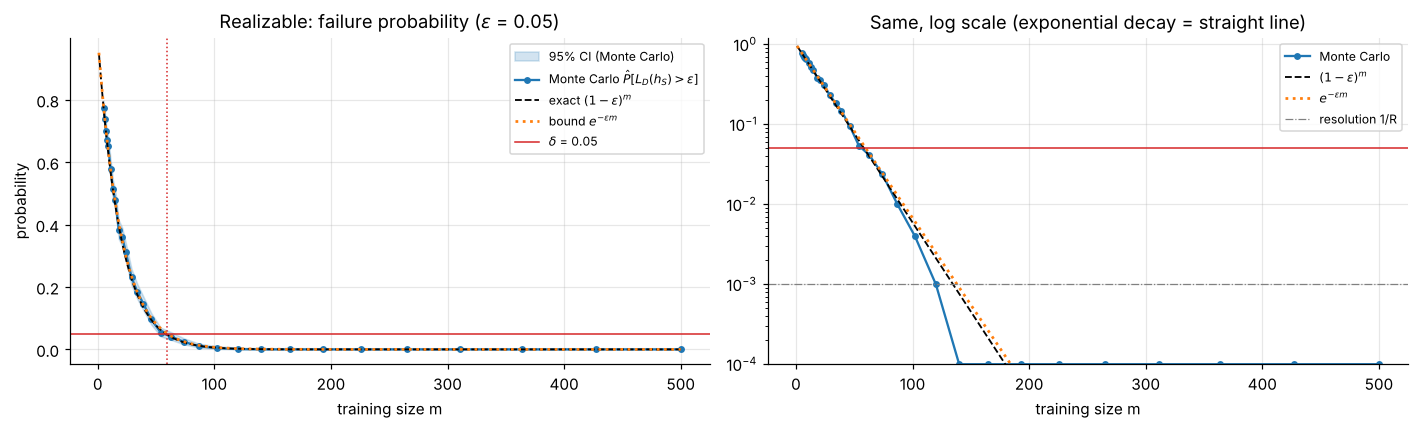

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.fill_between(M_FINE, lo, hi, color="tab:blue", alpha=0.2, label="95% CI (Monte Carlo)")
ax.plot(M_FINE, p_fail, "o-", ms=3.5, color="tab:blue", label=r"Monte Carlo $\hat P[L_{D}(h_S)>\varepsilon]$")
mm = np.arange(1, 501)
ax.plot(mm, (1 - EPS) ** mm, "k--", lw=1.2, label=r"exact $(1-\varepsilon)^m$")
ax.plot(mm, np.exp(-EPS * mm), ":", color="tab:orange", lw=1.8, label=r"bound $e^{-\varepsilon m}$")
ax.axhline(DELTA, color="tab:red", lw=1, label=rf"$\delta$ = {DELTA}")
ax.axvline(m_exact, color="tab:red", ls=":", lw=1)
ax.set_xlabel("training size m"); ax.set_ylabel("probability")
ax.set_title(rf"Realizable: failure probability ($\varepsilon$ = {EPS})")
ax.legend(fontsize=8)

ax = axes[1]
ax.semilogy(M_FINE, np.maximum(p_fail, 1 / (10 * R)), "o-", ms=3.5, color="tab:blue", label="Monte Carlo")
ax.semilogy(mm, (1 - EPS) ** mm, "k--", lw=1.2, label=r"$(1-\varepsilon)^m$")
ax.semilogy(mm, np.exp(-EPS * mm), ":", color="tab:orange", lw=1.8, label=r"$e^{-\varepsilon m}$")
ax.axhline(DELTA, color="tab:red", lw=1); ax.axhline(1 / R, color="grey", lw=0.8, ls="-.", label="resolution 1/R")
ax.set_ylim(1e-4, 1.2); ax.set_xlabel("training size m"); ax.set_title("Same, log scale (exponential decay = straight line)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observations.**
- The failure probability decreases **exponentially** with $m$ (a straight line on the log scale), and the Monte Carlo estimates fall on the exact curve $(1-\varepsilon)^m$, within their confidence intervals.
- The bound $e^{-\varepsilon m}$ is only slightly above the exact curve here, because $\ln(1-\varepsilon) \approx -\varepsilon$ for small $\varepsilon$.
- The PAC guarantee $\Pr[L_{\mathcal D,f}(h_S) \le \varepsilon] \ge 1-\delta$ is reached around $m \approx 60$: $m^\star = 59$ exactly, the bound gives 60, and the Monte Carlo grid first crosses $\delta$ at its next grid point after 59. The bound is almost tight for this class.
- On the log plot, points at zero are drawn at $1/(10R)$: once the true probability drops below $1/R = 10^{-3}$, 1000 repetitions can no longer resolve it.

### 4.3 Influence of $\varepsilon$, $\delta$ and $\theta$

PAC learnability claims the guarantee holds for **every** $\varepsilon, \delta$ and **every** target. We therefore vary the parameters instead of fixing them:
- the required sample size should scale like $1/\varepsilon$ (a smaller tolerance needs more data);
- it should grow only like $\log(1/\delta)$ (higher confidence is cheap);
- for $\varepsilon < \theta$ it should not depend on $\theta$ (the distribution of $\theta - \hat t$ does not depend on $\theta$ in that range).

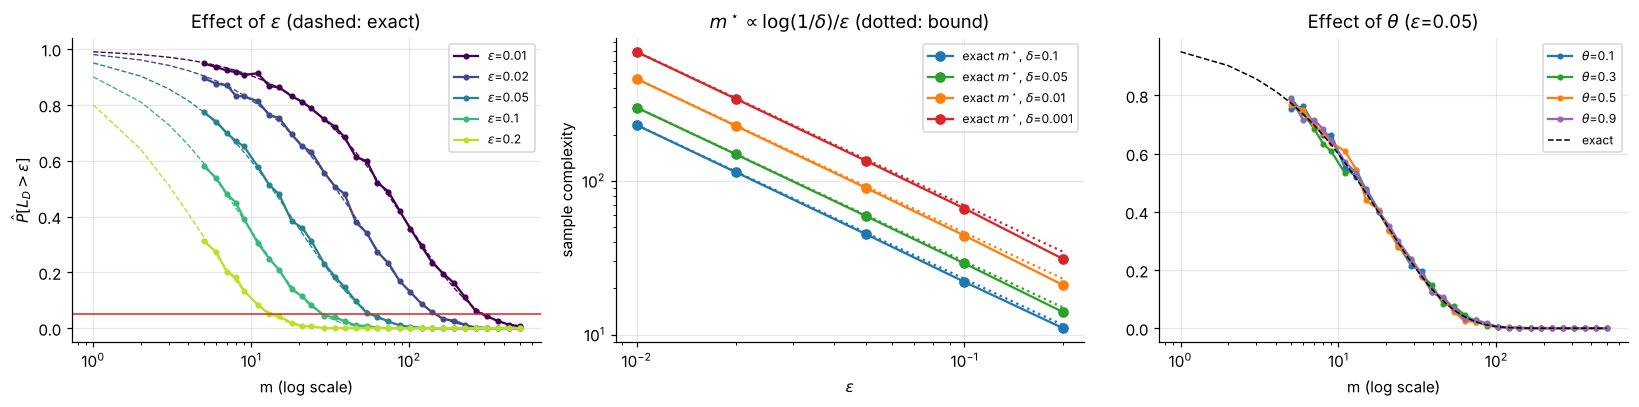

Exact sample complexity m*(eps, delta):
  delta=0.1    eps=0.01:  230  eps=0.02:  114  eps=0.05:   45  eps=0.1:   22  eps=0.2:   11
  delta=0.05   eps=0.01:  299  eps=0.02:  149  eps=0.05:   59  eps=0.1:   29  eps=0.2:   14
  delta=0.01   eps=0.01:  459  eps=0.02:  228  eps=0.05:   90  eps=0.1:   44  eps=0.2:   21
  delta=0.001  eps=0.01:  688  eps=0.02:  342  eps=0.05:  135  eps=0.1:   66  eps=0.2:   31


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

ax = axes[0]
for eps, c in zip([0.01, 0.02, 0.05, 0.1, 0.2], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    ax.plot(M_FINE, [np.mean(real[m][2] > eps) for m in M_FINE], "o-", ms=3, color=c, label=rf"$\varepsilon$={eps}")
    ax.plot(mm, (1 - eps) ** mm, "--", color=c, lw=0.9)
ax.axhline(DELTA, color="tab:red", lw=1); ax.set_xscale("log")
ax.set_xlabel("m (log scale)"); ax.set_ylabel(r"$\hat P[L_D > \varepsilon]$")
ax.set_title(r"Effect of $\varepsilon$ (dashed: exact)"); ax.legend(fontsize=8)

ax = axes[1]
eps_vals = np.array([0.01, 0.02, 0.05, 0.1, 0.2])
for d, c in zip([0.1, 0.05, 0.01, 0.001], ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
    ax.loglog(eps_vals, np.ceil(np.log(d) / np.log(1 - eps_vals)), "o-", color=c, label=rf"exact $m^\star$, $\delta$={d}")
    ax.loglog(eps_vals, np.log(1 / d) / eps_vals, ":", color=c)
ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel("sample complexity")
ax.set_title(r"$m^\star \propto \log(1/\delta)/\varepsilon$ (dotted: bound)"); ax.legend(fontsize=8)

ax = axes[2]
for th, c in zip([0.1, 0.3, 0.5, 0.9], ["tab:blue", "tab:green", "tab:orange", "tab:purple"]):
    ax.plot(M_FINE, [np.mean(run_mc(m, theta=th)[2] > EPS) for m in M_FINE], "o-", ms=3, color=c, label=rf"$\theta$={th}")
ax.plot(mm, (1 - EPS) ** mm, "k--", lw=1, label="exact")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)")
ax.set_title(rf"Effect of $\theta$ ($\varepsilon$={EPS})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Exact sample complexity m*(eps, delta):")
for d in [0.1, 0.05, 0.01, 0.001]:
    print(f"  delta={d:<6}", "  ".join(f"eps={e}: {int(np.ceil(np.log(d)/np.log(1-e))):>4}" for e in eps_vals))

**Observations.**
- Dividing $\varepsilon$ by 10 multiplies the required sample size by about 10 (slope $-1$ on the log-log plot): $m^\star \propto 1/\varepsilon$.
- Going from $\delta = 0.1$ to $\delta = 0.001$ (100× more confidence) only multiplies $m^\star$ by $\ln(1000)/\ln(10) = 3$: confidence is cheap, accuracy is expensive.
- The curves for different $\theta$ overlap: the guarantee is uniform over targets in the class, as the definition of PAC learnability requires.

### 4.4 Empirical vs. true error across repetitions, and the choice of ERM

In the realizable setting $L_S(h_S) = 0$ for every sample, while $\mathbb E[L_{\mathcal D,f}(h_S)] = \mathbb E[\theta - \hat t] = \int_0^\theta (1-s)^m\,ds = \dfrac{1-(1-\theta)^{m+1}}{m+1} \approx \dfrac{1}{m+1}$.

ERM is not unique here: any $t \in [\hat t, \hat t_{\text{right}})$, where $\hat t_{\text{right}}$ is the smallest point labelled 1, also has zero empirical error. We compare our left-endpoint rule with the **midpoint** rule $t = (\hat t + \hat t_{\text{right}})/2$. Both are valid ERM algorithms, so both satisfy the PAC guarantee, but their errors differ.

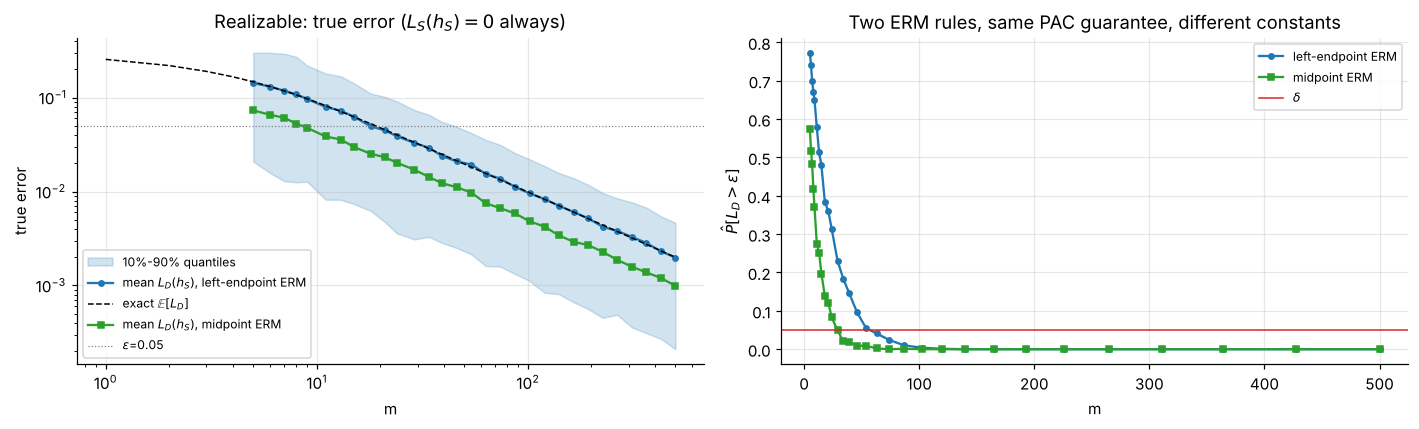

log-log slope of E[L_D] vs m (left-endpoint ERM): -0.95  (theory: -1)
Ratio of mean errors midpoint / left-endpoint at m=200: 0.52


In [10]:
def erm_midpoint_realizable(X, y):
    left = np.where(y == 0, X, 0.0).max(axis=1)
    right = np.where(y == 1, X, 1.0).min(axis=1)
    return (left + right) / 2

mean_ld, q10, q90, mean_ld_mid, p_mid = [], [], [], [], []
for m in M_FINE:
    X, y = generate_data(m, n_rep=R)
    t_left, _ = erm_threshold(X, y)
    t_mid = erm_midpoint_realizable(X, y)
    ld, ld_mid = true_risk(t_left), true_risk(t_mid)
    mean_ld.append(ld.mean()); q10.append(np.quantile(ld, 0.1)); q90.append(np.quantile(ld, 0.9))
    mean_ld_mid.append(ld_mid.mean()); p_mid.append(np.mean(ld_mid > EPS))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.fill_between(M_FINE, q10, q90, alpha=0.2, color="tab:blue", label="10%-90% quantiles")
ax.loglog(M_FINE, mean_ld, "o-", ms=3.5, color="tab:blue", label=r"mean $L_D(h_S)$, left-endpoint ERM")
ax.loglog(mm, (1 - (1 - THETA) ** (mm + 1)) / (mm + 1), "k--", lw=1, label=r"exact $\mathbb{E}[L_D]$")
ax.loglog(M_FINE, mean_ld_mid, "s-", ms=3.5, color="tab:green", label=r"mean $L_D(h_S)$, midpoint ERM")
ax.axhline(EPS, color="grey", lw=0.8, ls=":", label=rf"$\varepsilon$={EPS}")
ax.set_xlabel("m"); ax.set_ylabel("true error"); ax.set_title(r"Realizable: true error ($L_S(h_S)=0$ always)")
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(M_FINE, p_fail, "o-", ms=3.5, label="left-endpoint ERM")
ax.plot(M_FINE, p_mid, "s-", ms=3.5, color="tab:green", label="midpoint ERM")
ax.axhline(DELTA, color="tab:red", lw=1, label=r"$\delta$")
ax.set_xlabel("m"); ax.set_ylabel(r"$\hat P[L_D > \varepsilon]$"); ax.set_title("Two ERM rules, same PAC guarantee, different constants")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

slope = np.polyfit(np.log(M_FINE), np.log(mean_ld), 1)[0]
print(f"log-log slope of E[L_D] vs m (left-endpoint ERM): {slope:.2f}  (theory: -1)")
print(f"Ratio of mean errors midpoint / left-endpoint at m=200: {mean_ld_mid[list(M_FINE).index(min(M_FINE, key=lambda v: abs(v-200)))] / mean_ld[list(M_FINE).index(min(M_FINE, key=lambda v: abs(v-200)))]:.2f}")

**Observations.**
- The expected true error decays like $1/m$ (slope ≈ $-1$), matching the closed form. The spread across samples (shaded band) also shrinks: more data makes the outcome both better on average and more predictable.
- The midpoint rule roughly halves the expected error. Both rules have zero training error, so the training error cannot tell them apart; the difference is entirely a matter of how the learner generalises between the two classes. The PAC framework guarantees the *rate* for any ERM, not the constant.

## 5. From PAC to Agnostic PAC

We now flip each label with probability $\eta$. The realizability assumption fails: no $h \in \mathcal H$ has zero true error. From Section 3,
$$L_{\mathcal D}(h_t) = \eta + (1-2\eta)|t-\theta|, \qquad \min_{h\in\mathcal H} L_{\mathcal D}(h) = L_{\mathcal D}(h_\theta) = \eta.$$
Since $\eta < 1/2$, $P(y=1 \mid x) > 1/2 \iff x > \theta$, so $h_\theta$ is also the Bayes optimal predictor: here the class contains the best possible classifier, and the irreducible error $\eta$ comes from the noise only.

The relevant criterion is therefore the **agnostic** one (Definition 2.3): $L_{\mathcal D}(h_S) \le \min_{h} L_{\mathcal D}(h) + \varepsilon = \eta + \varepsilon$. We measure both the naive PAC event $\{L_{\mathcal D}(h_S) > \varepsilon\}$ and the agnostic event $\{L_{\mathcal D}(h_S) > \eta+\varepsilon\}$.

In [11]:
agn = {m: run_mc(m, eta=ETA) for m in M_FINE}

def summarise(res):
    ls = np.array([res[m][1].mean() for m in M_FINE])
    ld = np.array([res[m][2].mean() for m in M_FINE])
    p_ls0 = np.array([np.mean(res[m][1] == 0) for m in M_FINE])
    return ls, ld, p_ls0

ls_r, ld_r, p0_r = summarise(real)
ls_a, ld_a, p0_a = summarise(agn)
p_naive = np.array([np.mean(agn[m][2] > EPS) for m in M_FINE])
p_agn = np.array([np.mean(agn[m][2] > ETA + EPS) for m in M_FINE])

print(f"{'m':>4} | {'mean L_S':>8} | {'mean L_D':>8} | {'P[L_S=0]':>8} | {'P[L_D>eps]':>10} | {'P[L_D>eta+eps]':>14}   (agnostic, eta={ETA})")
for m in M_GRID:
    _, ls, ld = run_mc(m, eta=ETA)
    print(f"{m:>4} | {ls.mean():8.4f} | {ld.mean():8.4f} | {np.mean(ls==0):8.3f} | {np.mean(ld>EPS):10.3f} | {np.mean(ld>ETA+EPS):14.3f}")

   m | mean L_S | mean L_D | P[L_S=0] | P[L_D>eps] | P[L_D>eta+eps]   (agnostic, eta=0.1)
   5 |   0.0582 |   0.2332 |    0.729 |      1.000 |          0.752
  10 |   0.0806 |   0.1929 |    0.423 |      1.000 |          0.604
  20 |   0.0889 |   0.1513 |    0.136 |      1.000 |          0.373
  50 |   0.0969 |   0.1215 |    0.003 |      1.000 |          0.101
 100 |   0.0966 |   0.1110 |    0.000 |      1.000 |          0.013
 200 |   0.0997 |   0.1059 |    0.000 |      1.000 |          0.002


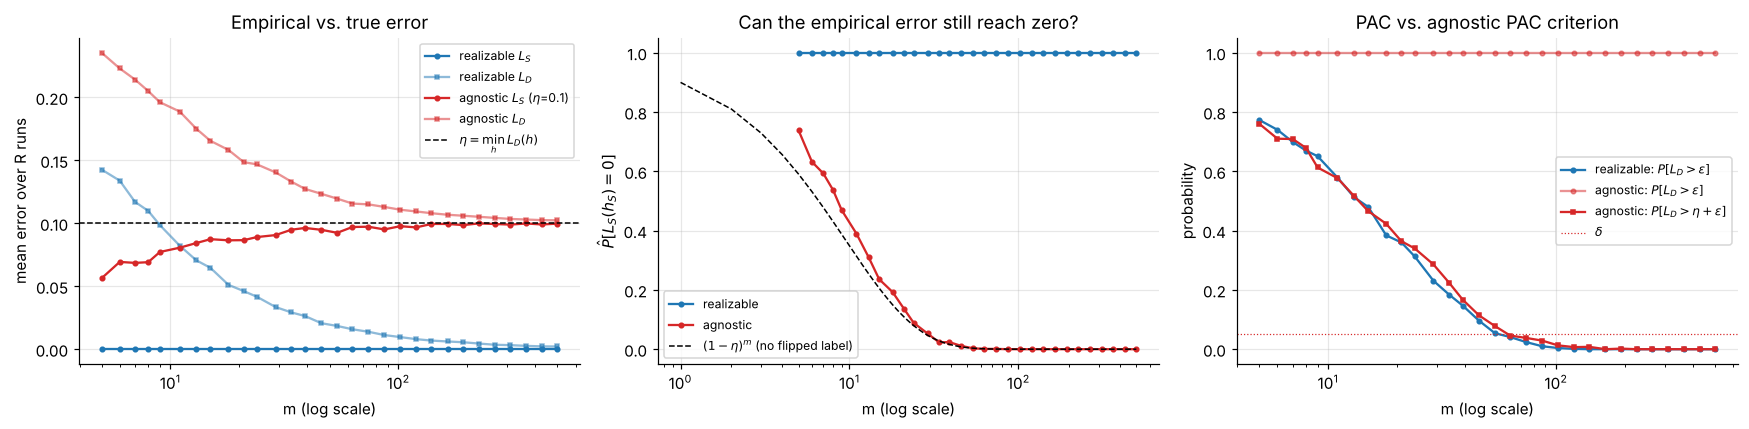

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ax = axes[0]
ax.plot(M_FINE, ls_r, "o-", ms=3, color="tab:blue", label=r"realizable $L_S$")
ax.plot(M_FINE, ld_r, "s-", ms=3, color="tab:blue", alpha=0.5, label=r"realizable $L_D$")
ax.plot(M_FINE, ls_a, "o-", ms=3, color="tab:red", label=rf"agnostic $L_S$ ($\eta$={ETA})")
ax.plot(M_FINE, ld_a, "s-", ms=3, color="tab:red", alpha=0.5, label=r"agnostic $L_D$")
ax.axhline(ETA, color="k", ls="--", lw=1, label=r"$\eta = \min_h L_D(h)$")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("mean error over R runs")
ax.set_title("Empirical vs. true error"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(M_FINE, p0_r, "o-", ms=3, color="tab:blue", label="realizable")
ax.plot(M_FINE, p0_a, "o-", ms=3, color="tab:red", label="agnostic")
ax.plot(mm, (1 - ETA) ** mm, "k--", lw=1, label=r"$(1-\eta)^m$ (no flipped label)")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel(r"$\hat P[L_S(h_S)=0]$")
ax.set_title("Can the empirical error still reach zero?"); ax.legend(fontsize=8)

ax = axes[2]
ax.plot(M_FINE, p_fail, "o-", ms=3, color="tab:blue", label=r"realizable: $P[L_D>\varepsilon]$")
ax.plot(M_FINE, p_naive, "o-", ms=3, color="tab:red", alpha=0.5, label=r"agnostic: $P[L_D>\varepsilon]$")
ax.plot(M_FINE, p_agn, "s-", ms=3, color="tab:red", label=r"agnostic: $P[L_D>\eta+\varepsilon]$")
ax.axhline(DELTA, color="tab:red", lw=0.8, ls=":", label=r"$\delta$")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("probability")
ax.set_title("PAC vs. agnostic PAC criterion"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observations.**
- **Can the empirical error still reach zero?** Only by luck, for very small samples. $L_S(h_S)=0$ requires that the flipped labels can still be separated by some threshold, which is at least as likely as having no flipped label at all, $(1-\eta)^m$ (dashed curve). That probability vanishes quickly: at $m=50$ it is already $0.9^{50} \approx 0.005$. For large $m$, $L_S(h_S)$ converges to $\eta$, from slightly below: ERM uses its freedom to fit some of the noise, so the training error is optimistically biased.
- **The true error converges to $\eta$, not to 0.** The naive PAC event $\{L_{\mathcal D}(h_S) > \varepsilon\}$ has probability 1 for every $m$, since $\eta = 0.1 > \varepsilon = 0.05$. More data cannot remove noise. Under the PAC criterion, this problem would look unlearnable.
- **Does more data still help?** Yes, once success is measured relative to the best achievable error: $\Pr[L_{\mathcal D}(h_S) > \eta + \varepsilon]$ goes to 0, i.e. ERM is an agnostic PAC learner here. What more data buys is not a smaller error than $\eta$ but closeness to the best hypothesis in $\mathcal H$.

### 5.1 Effect of the noise level $\eta$

The two frameworks only differ by the reference point ($0$ vs. $\min_h L_{\mathcal D}(h)$), but noise also makes learning *slower*: the excess risk $L_{\mathcal D}(h_S) - \eta = (1-2\eta)|\hat t-\theta|$ is driven by how well the sample locates $\theta$, and flipped labels near $\theta$ blur that location. As $\eta \to 1/2$, the labels carry no information about $\theta$ at all.

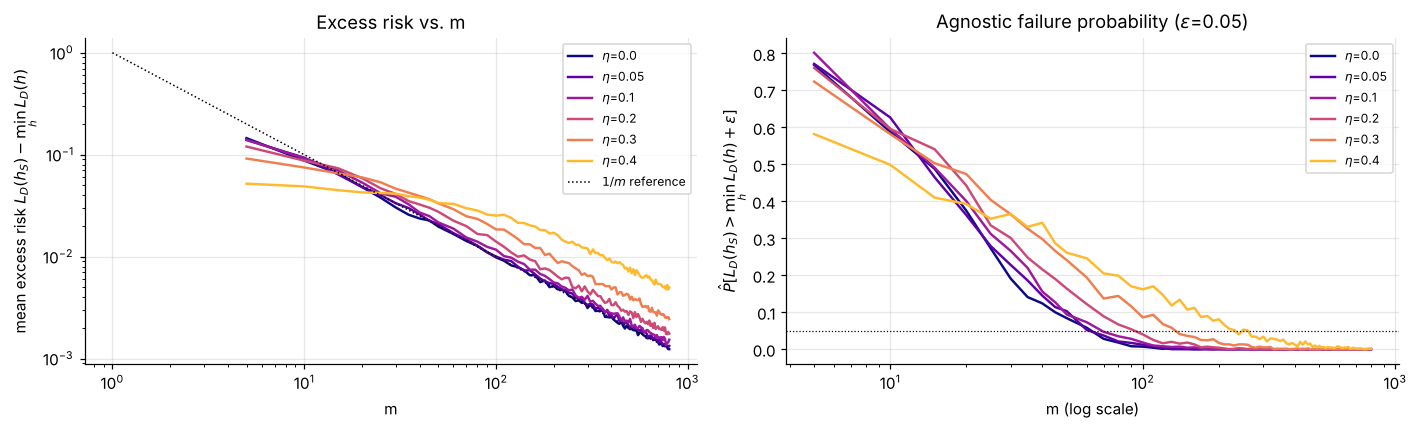

Smallest m (grid step 10, R=1000) with P[excess > eps] <= delta=0.05, and log-log slope of mean excess risk (m >= 50):
  eta = 0.0 : m =    70   slope = -1.00
  eta = 0.05: m =    70   slope = -0.99
  eta = 0.1 : m =    70   slope = -1.00
  eta = 0.2 : m =   100   slope = -0.99
  eta = 0.3 : m =   140   slope = -0.97
  eta = 0.4 : m =   240   slope = -0.78


In [13]:
ETAS_SWEEP = [0.0] + ETAS + [0.4]
M_SWEEP = np.unique(np.concatenate([np.arange(5, 50, 5), np.arange(50, 801, 10)]))  # dense grid for m_needed
res_eta = {eta: {m: run_mc(m, eta=eta) for m in M_SWEEP} for eta in ETAS_SWEEP}

colors = dict(zip(ETAS_SWEEP, plt.cm.plasma(np.linspace(0, 0.85, len(ETAS_SWEEP)))))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
m_needed, slopes = {}, {}
for eta, res in res_eta.items():
    excess = np.array([(res[m][2] - eta).mean() for m in M_SWEEP])
    p = np.array([np.mean(res[m][2] - eta > EPS) for m in M_SWEEP])
    m_needed[eta] = next((int(m) for m, v in zip(M_SWEEP, p) if v <= DELTA), None)
    sel = M_SWEEP >= 50
    slopes[eta] = np.polyfit(np.log(M_SWEEP[sel]), np.log(excess[sel]), 1)[0]
    axes[0].loglog(M_SWEEP, excess, "-", lw=1.6, color=colors[eta], label=rf"$\eta$={eta}")
    axes[1].plot(M_SWEEP, p, "-", lw=1.6, color=colors[eta], label=rf"$\eta$={eta}")
mm = np.arange(1, 801)
axes[0].loglog(mm, 1 / mm, "k:", lw=1, label=r"$1/m$ reference")
axes[0].set_xlabel("m"); axes[0].set_ylabel(r"mean excess risk $L_D(h_S) - \min_h L_D(h)$")
axes[0].set_title("Excess risk vs. m"); axes[0].legend(fontsize=8)
axes[1].axhline(DELTA, color="k", lw=0.8, ls=":")
axes[1].set_xscale("log"); axes[1].set_xlabel("m (log scale)")
axes[1].set_ylabel(r"$\hat P[L_D(h_S) > \min_h L_D(h) + \varepsilon]$")
axes[1].set_title(rf"Agnostic failure probability ($\varepsilon$={EPS})"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Smallest m (grid step 10, R={R}) with P[excess > eps] <= delta={DELTA}, and log-log slope of mean excess risk (m >= 50):")
for eta in ETAS_SWEEP:
    mn = m_needed[eta]
    print(f"  eta = {eta:<4}: m = {mn if mn is not None else '> ' + str(M_SWEEP.max()):>5}   slope = {slopes[eta]:.2f}")

**Observations.**
- For every $\eta < 1/2$ the excess risk still goes to 0, so the class remains agnostic PAC learnable. The required sample size grows with $\eta$, slowly at first and then sharply as $\eta$ approaches $1/2$ (see the printed table: roughly ×3.5 between $\eta=0$ and $\eta=0.4$).
- Why it grows only slowly at low noise: the excess risk is $(1-2\eta)|\hat t - \theta|$, so the factor $(1-2\eta)$ partly compensates for the less precise $\hat t$. The criterion $\text{excess} > \varepsilon$ is equivalent to $|\hat t-\theta| > \varepsilon/(1-2\eta)$, a *looser* condition on the threshold when $\eta$ grows.
- On this particular problem the excess risk still decreases like $1/m$ (fitted slopes ≈ $-1$). The exception is $\eta = 0.4$, where the slope is flatter because $m \le 800$ is not yet in the asymptotic regime. The general agnostic guarantees seen in the course (via uniform convergence, Session 3) scale like $1/\varepsilon^2$, i.e. an excess risk of order $1/\sqrt m$. That is a *worst-case* rate over all distributions. Here the noise is bounded away from $1/2$ ($\eta$ is the same everywhere), which makes the problem easier than the worst case. This is a reminder that sample-complexity bounds are sufficient conditions, not exact descriptions of every problem.

## 6. Conclusion: PAC vs. Agnostic PAC

| | Realizable (PAC) | Agnostic (APAC) |
|---|---|---|
| Assumption | $f_\theta \in \mathcal H$, clean labels | labels flipped with probability $\eta$; no perfect $h$ |
| Empirical error of ERM | always exactly 0 | positive; 0 only by chance for tiny $m$; tends to $\eta$ from below |
| True error of ERM | $\to 0$, mean $\approx 1/(m+1)$ | $\to \eta = \min_h L_{\mathcal D}(h)$, never below |
| Success criterion | $L_{\mathcal D}(h_S) \le \varepsilon$ | $L_{\mathcal D}(h_S) \le \min_h L_{\mathcal D}(h) + \varepsilon$ |
| Failure probability vs. $m$ | $(1-\varepsilon)^m$, exponential decay, verified | naive criterion: stuck at 1 when $\eta > \varepsilon$; agnostic criterion: $\to 0$ |
| Sample complexity | $\approx \ln(1/\delta)/\varepsilon$ (≈ 60 for $\varepsilon=\delta=0.05$) | grows with $\eta$, sharply as $\eta \to 1/2$ (≈ 3.5× larger at $\eta=0.4$) |

1. **ERM on thresholds is a PAC learner.** The failure probability decreases exponentially and matches the exact law $(1-\varepsilon)^m$. The sample complexity scales like $\log(1/\delta)/\varepsilon$, and the behaviour does not depend on $\theta$. The class is infinite, so this also shows that finiteness of $\mathcal H$ is not necessary for learnability.
2. **With noise, the target leaves the class**, the empirical error stops reaching zero, and the true error is bounded below by $\eta$. Measured by the PAC criterion, more data looks useless once $\varepsilon < \eta$.
3. **The agnostic framework restores a meaningful guarantee** by comparing to the best hypothesis in $\mathcal H$: ERM's excess risk still vanishes with $m$. More data does not beat the noise, it brings us closer to the best achievable classifier.
4. **The training error is not a reliable proxy for the true error**: it is 0 regardless of quality in the realizable case, and optimistically biased in the agnostic case. This is what motivates the uniform-convergence analysis of the next session.